In [1]:
import pandas as pd
import seaborn as sns

In [2]:
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [33]:
titanic_data = sns.load_dataset('titanic')
titanic_data

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [4]:
titanic_data.shape

(891, 15)

In [5]:
titanic_data.dtypes

survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

In [34]:
titanic_data[titanic_data.duplicated()]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
47,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True
76,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
77,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
87,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
95,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
870,0,3,male,26.0,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
877,0,3,male,19.0,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
878,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
884,0,3,male,25.0,0,0,7.0500,S,Third,man,True,NaN,Southampton,no,True


In [35]:
titanic_data.drop_duplicates(inplace=True)

In [36]:
titanic_data[titanic_data.duplicated()]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone


In [9]:
titanic_data.shape

(784, 15)

In [37]:
titanic_data.isna().sum()

survived         0
pclass           0
sex              0
age            106
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           582
embark_town      2
alive            0
alone            0
dtype: int64

In [38]:
titanic_data["age"]= titanic_data["age"].fillna(titanic_data["age"].mean())
titanic_data["deck"] =titanic_data["deck"].fillna(titanic_data["deck"].mode()[0])

In [39]:
titanic_data.dtypes

survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

In [40]:
titanic_data["sex"] = titanic_data["sex"].astype(bool)

In [41]:
titanic_data.dtypes

survived          int64
pclass            int64
sex                bool
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

In [42]:
titanic_data["who"].value_counts()

who
man      451
woman    251
child     82
Name: count, dtype: int64

In [43]:
titanic_data = pd.get_dummies(data=titanic_data, columns=["who"], drop_first=True)

In [45]:
titanic_data = pd.get_dummies(data=titanic_data, columns=["embarked"], drop_first=True)

KeyError: "None of [Index(['embarked'], dtype='object')] are in the [columns]"

In [47]:
titanic_data = pd.get_dummies(data=titanic_data, columns=["embark_town"], drop_first=True)

KeyError: "None of [Index(['embark_town'], dtype='object')] are in the [columns]"

In [48]:
titanic_data = titanic_data.drop(columns=["alive"])

In [49]:
titanic_data.dtypes

survived                      int64
pclass                        int64
sex                            bool
age                         float64
sibsp                         int64
parch                         int64
fare                        float64
class                      category
adult_male                     bool
deck                       category
alone                          bool
who_man                        bool
who_woman                      bool
embarked_Q                     bool
embarked_S                     bool
embark_town_Queenstown         bool
embark_town_Southampton        bool
dtype: object

In [50]:
titanic_data.isna().sum()

survived                   0
pclass                     0
sex                        0
age                        0
sibsp                      0
parch                      0
fare                       0
class                      0
adult_male                 0
deck                       0
alone                      0
who_man                    0
who_woman                  0
embarked_Q                 0
embarked_S                 0
embark_town_Queenstown     0
embark_town_Southampton    0
dtype: int64

In [51]:
X = titanic_data.drop(columns=["survived"])
X

,pclass,sex,age,sibsp,parch,fare,class,adult_male,deck,alone,who_man,who_woman,embarked_Q,embarked_S,embark_town_Queenstown,embark_town_Southampton
0,3,True,22.000000,1,0,7.2500,Third,True,C,False,True,False,False,True,False,True
1,1,True,38.000000,1,0,71.2833,First,False,C,False,False,True,False,False,False,False
2,3,True,26.000000,0,0,7.9250,Third,False,C,True,False,True,False,True,False,True
3,1,True,35.000000,1,0,53.1000,First,False,C,False,False,True,False,True,False,True
4,3,True,35.000000,0,0,8.0500,Third,True,C,True,True,False,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,3,True,39.000000,0,5,29.1250,Third,False,C,False,False,True,True,False,True,False
887,1,True,19.000000,0,0,30.0000,First,False,B,True,False,True,False,True,False,True
888,3,True,29.869351,1,2,23.4500,Third,False,C,False,False,True,False,True,False,True
889,1,True,26.000000,0,0,30.0000,First,True,C,True,True,False,False,False,False,False


In [52]:
y = titanic_data["survived"]
y

0      0
1      1
2      1
3      1
4      0
      ..
885    0
887    1
888    0
889    1
890    0
Name: survived, Length: 784, dtype: int64

In [24]:
titanic_data.dtypes

survived                      int64
pclass                        int64
sex                            bool
age                         float64
sibsp                         int64
parch                         int64
fare                        float64
class                      category
adult_male                     bool
deck                       category
alone                          bool
who_man                        bool
who_woman                      bool
embarked_Q                     bool
embarked_S                     bool
embark_town_Queenstown         bool
embark_town_Southampton        bool
dtype: object

In [53]:
X = pd.get_dummies(X, drop_first=True)
X

,pclass,sex,age,sibsp,parch,fare,adult_male,alone,who_man,who_woman,...,embark_town_Queenstown,embark_town_Southampton,class_Second,class_Third,deck_B,deck_C,deck_D,deck_E,deck_F,deck_G
0,3,True,22.000000,1,0,7.2500,True,False,True,False,...,False,True,False,True,False,True,False,False,False,False
1,1,True,38.000000,1,0,71.2833,False,False,False,True,...,False,False,False,False,False,True,False,False,False,False
2,3,True,26.000000,0,0,7.9250,False,True,False,True,...,False,True,False,True,False,True,False,False,False,False
3,1,True,35.000000,1,0,53.1000,False,False,False,True,...,False,True,False,False,False,True,False,False,False,False
4,3,True,35.000000,0,0,8.0500,True,True,True,False,...,False,True,False,True,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,3,True,39.000000,0,5,29.1250,False,False,False,True,...,True,False,False,True,False,True,False,False,False,False
887,1,True,19.000000,0,0,30.0000,False,True,False,True,...,False,True,False,False,True,False,False,False,False,False
888,3,True,29.869351,1,2,23.4500,False,False,False,True,...,False,True,False,True,False,True,False,False,False,False
889,1,True,26.000000,0,0,30.0000,True,True,True,False,...,False,False,False,False,False,True,False,False,False,False


In [54]:
from sklearn.model_selection import train_test_split

In [55]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.20, random_state=43)

In [56]:
X_train, X_test, y_train, y_test

(     pclass   sex        age  sibsp  parch      fare  adult_male  alone  \
 314       2  True  43.000000      1      1   26.2500        True  False   
 746       3  True  16.000000      1      1   20.2500        True  False   
 366       1  True  60.000000      1      0   75.2500       False  False   
 527       1  True  29.869351      0      0  221.7792        True   True   
 337       1  True  41.000000      0      0  134.5000       False   True   
 ..      ...   ...        ...    ...    ...       ...         ...    ...   
 16        3  True   2.000000      4      1   29.1250       False  False   
 59        3  True  11.000000      5      2   46.9000       False  False   
 294       3  True  24.000000      0      0    7.8958        True   True   
 271       3  True  25.000000      0      0    0.0000        True   True   
 345       2  True  24.000000      0      0   13.0000       False   True   
 
      who_man  who_woman  ...  embark_town_Queenstown  embark_town_Southampton  \
 314

In [29]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

In [96]:
# This will automatically find all object/string columns and convert them to dummy variables
X = pd.get_dummies(X, drop_first=True)

# Then do your split again
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=43)

# Now your model will fit successfully!
# dt = DecisionTreeClassifier(criterion='entropy', max_depth=5)
# dt = DecisionTreeClassifier(criterion='gini', max_depth=7)  

# dt= DecisionTreeClassifier()
# GridSearchCV(estimator=dt,param_grid={"max_depth":  [5,6,7,8,9] , "criterion": ['gini','entropy']})

dt = GridSearchCV(
    estimator=DecisionTreeClassifier(),
    param_grid={
        'criterion': ['gini', 'entropy'],
        'max_depth': [3, 4, 5, 6, 7]
    },
    scoring='roc_auc',  # Explicitly optimizes for AUC instead of accuracy
    cv=5
)

dt.fit(X_train, y_train)

print("Best Parameters for highest AUC:", dt.best_params_)
print("Best CV AUC Score:", dt.best_score_)
# dt.fit(X_train, y_train)

Best Parameters for highest AUC: {'criterion': 'gini', 'max_depth': 3}
Best CV AUC Score: 0.8324434269563682


In [97]:
y_test_pred = dt.predict(X_test)
y_test_pred

array([1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1,
       0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1,
       1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1])

In [60]:
from sklearn.metrics import accuracy_score, classification_report

In [98]:
print (classification_report(y_test,y_test_pred))

              precision    recall  f1-score   support

           0       0.86      0.86      0.86        88
           1       0.83      0.83      0.83        69

    accuracy                           0.85       157
   macro avg       0.84      0.84      0.84       157
weighted avg       0.85      0.85      0.85       157



In [107]:
pd.Series(dt.feature_importances_, index=X_train.columns).sort_values(ascending=False)

AttributeError: 'GridSearchCV' object has no attribute 'feature_importances_'

## ROC curve --> Receiver Operating Characteristics

In [63]:
from sklearn.metrics import roc_curve, roc_auc_score

In [101]:
y_test_proba = dt.predict_proba(X_test)[:, 1]
y_test_proba

array([0.98648649, 0.41975309, 0.13483146, 0.41975309, 0.98648649,
       0.09375   , 0.13483146, 0.13483146, 0.98648649, 0.98648649,
       0.13483146, 0.55102041, 0.13483146, 0.89473684, 0.41975309,
       0.98648649, 0.13483146, 0.13483146, 0.98648649, 0.89473684,
       0.89473684, 0.13483146, 0.41975309, 0.89473684, 0.13483146,
       0.13483146, 0.13483146, 0.13483146, 0.13483146, 0.55102041,
       0.13483146, 0.89473684, 0.55102041, 0.55102041, 1.        ,
       0.89473684, 0.13483146, 0.41975309, 0.98648649, 0.55102041,
       0.13483146, 0.89473684, 0.98648649, 0.98648649, 0.89473684,
       0.55102041, 0.13483146, 0.41975309, 0.13483146, 0.13483146,
       0.98648649, 0.55102041, 0.89473684, 0.13483146, 0.13483146,
       0.41975309, 0.41975309, 0.13483146, 0.41975309, 0.11764706,
       0.11764706, 0.13483146, 0.55102041, 0.13483146, 0.13483146,
       0.13483146, 0.13483146, 0.55102041, 0.89473684, 0.13483146,
       0.98648649, 0.09375   , 0.98648649, 0.98648649, 0.41975

In [102]:
fpr, tpr , thresholds = roc_curve(y_test, y_test_proba)
fpr, tpr , thresholds

(array([0.        , 0.01136364, 0.02272727, 0.03409091, 0.13636364,
        0.25      , 0.90909091, 0.95454545, 1.        ]),
 array([0.        , 0.        , 0.44927536, 0.65217391, 0.82608696,
        0.89855072, 0.98550725, 1.        , 1.        ]),
 array([       inf, 1.        , 0.98648649, 0.89473684, 0.55102041,
        0.41975309, 0.13483146, 0.11764706, 0.09375   ]))

In [103]:
auc = roc_auc_score(y_test, y_test_proba)
print (auc)

0.893857048748353


In [104]:
from matplotlib import pyplot as plt

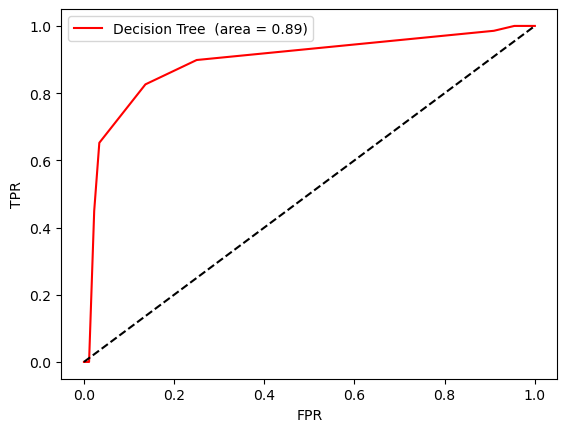

In [105]:
plt.plot(fpr, tpr, color='red', label='Decision Tree  (area = %0.2f)'% auc)
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.show()

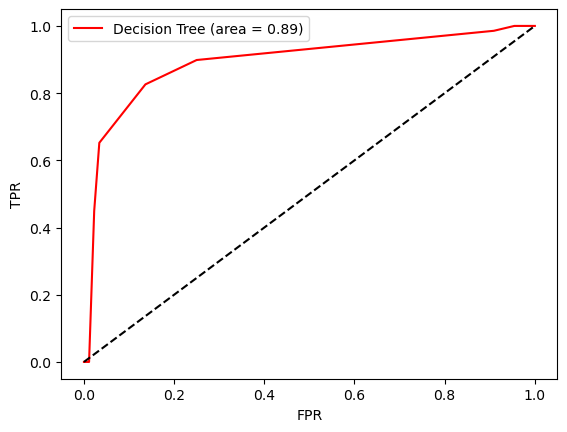

In [106]:
plt.plot(fpr, tpr, color='red', label='Decision Tree (area = %0.2f)'% auc)
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.show()